# 04. SQL Analytics Lab

**Procurement Intelligence Platform** | Notebook 04 of 13

Ten procurement questions answered with SQL on the warehouse: window functions, percentiles, gaps-and-islands, ASOF joins, cohorts, Pareto analysis, process mining and a type-2 slowly changing dimension.

| | |
|---|---|
| **Inputs** | `data/warehouse/p2p.duckdb` (marts) |
| **Outputs** | Answers and insights; reusable queries for the dashboard SQL Explorer |
| **Skills shown** | Advanced SQL (DuckDB dialect, portable to PostgreSQL and BigQuery) |

Each section states the business question, shows the query and ends with the insight. The queries run on DuckDB; a portability note at
the end lists the few dialect differences for PostgreSQL and BigQuery.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from p2p.viz.theme import use_matplotlib, BRAND, SERIES, ORIGIN_COLORS, STATUS, shade_shocks
use_matplotlib()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
from p2p.data import connect
con = connect()

def sql(q: str) -> pd.DataFrame:
    """Run a query on the warehouse and return a DataFrame."""
    return con.execute(q).df()

## Q1. Is the backlog growing or shrinking, week by week?
*Window functions: `LAG`, running sums, moving averages.*

,week_start,created,closed,open_lines,net_change,ytd_net_change,created_13w_avg,closed_13w_avg
202,2025-11-17,209.000,201.000,"2,227.000",8.000,469.000,196.615,195.385
203,2025-11-24,201.000,206.000,"2,222.000",-5.000,464.000,194.462,196.615
204,2025-12-01,218.000,191.000,"2,249.000",27.000,491.000,200.385,197.538
205,2025-12-08,150.000,203.000,"2,196.000",-53.000,438.000,197.692,197.615
206,2025-12-15,153.000,191.000,"2,158.000",-38.000,400.000,198.385,198.154
207,2025-12-22,84.000,200.000,"2,042.000",-116.000,284.000,183.769,198.000


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


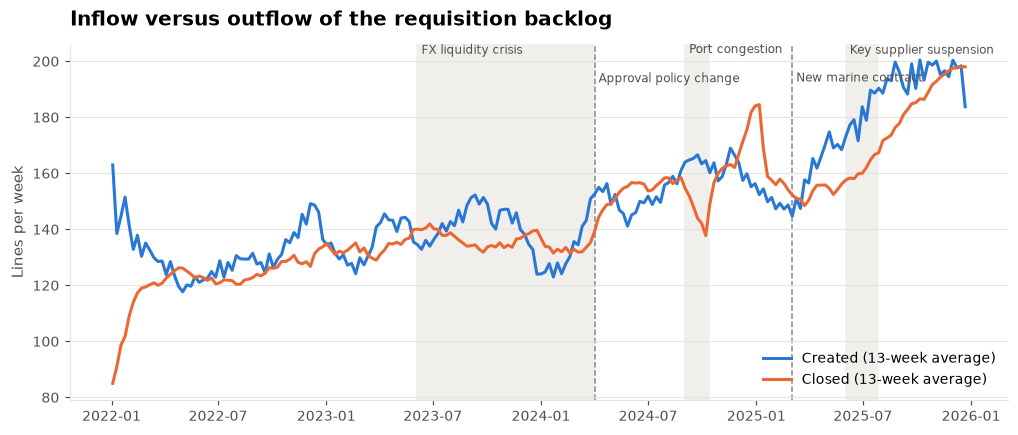

In [3]:
q1 = sql("""
    with weekly as (
        select week_start,
               sum(created_lines)                         as created,
               sum(received_lines + cancelled_lines)      as closed,
               sum(open_lines)                            as open_lines
        from marts.fct_backlog_weekly
        group by week_start
    )
    select
        week_start,
        created, closed, open_lines,
        open_lines - lag(open_lines) over (order by week_start)                       as net_change,
        sum(created - closed) over (partition by year(week_start) order by week_start) as ytd_net_change,
        avg(created) over (order by week_start rows between 12 preceding and current row) as created_13w_avg,
        avg(closed)  over (order by week_start rows between 12 preceding and current row) as closed_13w_avg
    from weekly
    order by week_start
""")
display(q1.tail(6))

fig, ax = plt.subplots()
ax.plot(q1.week_start, q1.created_13w_avg, label="Created (13-week average)", color=SERIES[0])
ax.plot(q1.week_start, q1.closed_13w_avg, label="Closed (13-week average)", color=SERIES[1])
shade_shocks(ax); ax.legend(loc="lower right"); ax.set_ylabel("Lines per week")
ax.set_title("Inflow versus outflow of the requisition backlog")
plt.show()

**Insight.** Whenever the orange line (closures) falls below the blue line (new lines), the backlog grows. That happened during the FX
crisis (foreign downpayments stalled), around the port congestion (deliveries held) and again in 2025 when the new marine contract
raised demand. Outflow always catches up, but with a lag of several weeks: the backlog reacts to shocks slowly, which is exactly why
a forward-looking forecast is valuable.

## Q2. How long do suppliers really take, and which categories are slowest?
*Ordered-set aggregates: `median`, `quantile_cont`; `dense_rank`.*

In [4]:
q2 = sql("""
    select supplier_origin, category,
           count(*)                                        as delivered_lines,
           median(po_to_delivery_days)                     as p50_days,
           quantile_cont(po_to_delivery_days, 0.9)         as p90_days,
           round(quantile_cont(po_to_delivery_days, 0.9) / median(po_to_delivery_days), 2) as tail_ratio,
           dense_rank() over (partition by supplier_origin order by median(po_to_delivery_days) desc) as slowest_rank
    from marts.fct_requisition_line
    where delivered_on is not null and supplier_origin in ('Local', 'Foreign')
    group by supplier_origin, category
    qualify slowest_rank <= 3
    order by supplier_origin, slowest_rank
""")
display(q2)

,supplier_origin,category,delivered_lines,p50_days,p90_days,tail_ratio,slowest_rank
0,Foreign,Bearings and Seals,2579,116.000,172.200,1.480,1
1,Foreign,Electronics and Controls,990,116.000,188.100,1.620,1
2,Foreign,Hydraulics,1277,112.000,174.400,1.560,2
3,Foreign,Engine Parts,2309,112.000,175.000,1.560,2
4,Foreign,Tyres and Tracks,739,101.000,158.000,1.560,3
5,Local,Electronics and Controls,546,28.000,47.000,1.680,1
6,Local,Hydraulics,1720,24.000,46.000,1.920,2
7,Local,Engine Parts,2177,24.000,42.000,1.750,2
8,Local,Bearings and Seals,1459,22.000,39.000,1.770,3


**Insight.** The slowest foreign categories (bearings and seals, electronics, engine parts, hydraulics) take close to 4 months at the
median and about 6 months at P90. Locally the same categories take 3 to 4 weeks. The P90 to P50 ratio of 1.5 to 1.9 matters for
planning: promising the median date to Maintenance means being late half of the time. Planning should promise P80 or P90 dates for
critical equipment.

## Q3. How long did the backlog keep growing without a break?
*Gaps-and-islands: consecutive weeks of growth identified with the row-number difference technique.*

In [5]:
q3 = sql("""
    with weekly as (
        select week_start, sum(open_lines) as open_lines
        from marts.fct_backlog_weekly group by week_start
    ),
    flagged as (
        select *, open_lines > lag(open_lines) over (order by week_start) as grew
        from weekly
    ),
    islands as (
        select *,
               row_number() over (order by week_start)
             - row_number() over (partition by grew order by week_start) as island_id
        from flagged
        where grew is not null
    )
    select min(week_start) as streak_start, max(week_start) as streak_end, count(*) as weeks_growing,
           max(open_lines) - min(open_lines) as lines_added
    from islands
    where grew
    group by island_id
    order by weeks_growing desc
    limit 5
""")
display(q3)

,streak_start,streak_end,weeks_growing,lines_added
0,2024-08-26,2024-10-07,7,353.000
1,2023-02-13,2023-03-13,5,171.000
2,2022-09-26,2022-10-24,5,64.000
3,2025-04-21,2025-05-19,5,86.000
4,2022-05-16,2022-06-06,4,25.000


**Insight.** The longest streak is the port congestion: 7 consecutive weeks of growth that added about 350 lines, because deliveries
were held while new requisitions kept coming. The next ones follow the 2025 marine contract and early 2023. Streaks of 5 or more weeks
are a useful **early-warning rule** for the dashboard: one week of growth is noise, five in a row is a trend that needs a decision.

## Q4. What did the FX crisis cost in local currency?
*`ASOF JOIN`: attach the exchange rate in force on each payment date.*

In [6]:
q4 = sql("""
    select date_trunc('quarter', p.paid_on)              as quarter,
           round(sum(p.amount_usd) / 1e6, 2)             as foreign_paid_musd,
           round(sum(p.amount_usd * fx.lcu_per_usd) / 1e9, 2) as foreign_paid_bn_lcu,
           round(avg(fx.lcu_per_usd), 0)                 as avg_rate
    from marts.fct_payment p
    asof join staging.stg_fx_rates fx on p.paid_on >= fx.rate_date
    where p.supplier_origin = 'Foreign' and p.paid_on >= '2022-01-01'
    group by all order by quarter
""")
display(q4)

,quarter,foreign_paid_musd,foreign_paid_bn_lcu,avg_rate
0,2022-01-01,1.610,1.360,842.000
1,2022-04-01,1.870,1.650,883.000
2,2022-07-01,1.780,1.640,918.000
3,2022-10-01,1.880,1.790,951.000
4,2023-01-01,2.070,2.000,973.000
5,2023-04-01,2.240,2.210,987.000
6,2023-07-01,2.040,2.980,"1,468.000"
7,2023-10-01,2.150,3.550,"1,647.000"
8,2024-01-01,2.060,3.320,"1,608.000"
9,2024-04-01,2.560,4.600,"1,795.000"


**Insight.** The USD bill for foreign parts grew gradually, but in local currency the cost jumped by more than half after mid-2023
because each dollar cost about 55% more. This is the hidden reason Finance slowed foreign downpayments, and why local sourcing became
attractive (notebook 10 quantifies the trade-off).

## Q5. How quickly do requisitions get fulfilled, by creation cohort?
*Cohort analysis with conditional aggregation.*

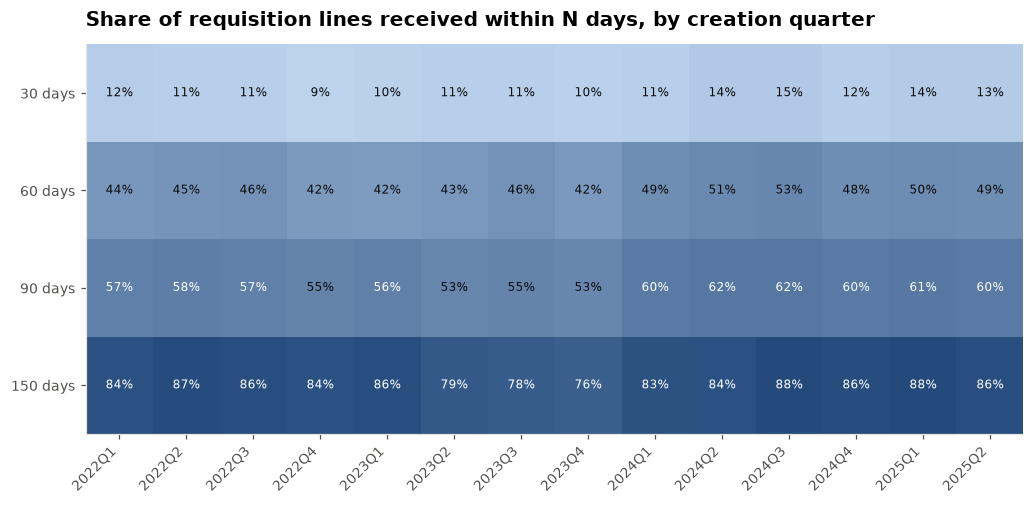

In [7]:
q5 = sql("""
    select date_trunc('quarter', pr_created_on)                                         as cohort,
           count(*)                                                                     as lines,
           avg(case when gr_posted_on <= pr_created_on + interval 30 day then 1 else 0 end)  as received_30d,
           avg(case when gr_posted_on <= pr_created_on + interval 60 day then 1 else 0 end)  as received_60d,
           avg(case when gr_posted_on <= pr_created_on + interval 90 day then 1 else 0 end)  as received_90d,
           avg(case when gr_posted_on <= pr_created_on + interval 150 day then 1 else 0 end) as received_150d
    from marts.fct_requisition_line
    where pr_created_on between '2022-01-01' and '2025-06-30' and lifecycle_status <> 'Cancelled'
    group by all order by cohort
""")
import matplotlib.colors as mcolors
cmap = mcolors.LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#0d366b"])
m = q5.set_index(q5.cohort.dt.to_period("Q").astype(str))[["received_30d", "received_60d", "received_90d", "received_150d"]]
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(m.T.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(m))); ax.set_xticklabels(m.index, rotation=45, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(["30 days", "60 days", "90 days", "150 days"])
for i in range(4):
    for j in range(len(m)):
        v = m.T.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.55 else BRAND["ink"])
ax.grid(False); ax.set_title("Share of requisition lines received within N days, by creation quarter")
plt.show()

**Insight.** Normally about 45% of the lines are received within 60 days and about 85% within 150 days. The cohorts raised in 2023 Q2
to Q4 fall to 76 to 79% at 150 days (FX crisis), and from 2024 Q1 the 60-day share climbs to about 50% after the approval policy change.
The cohort view separates "when the request was made" from "when it was closed", which a monthly KPI cannot do.

## Q6. Which suppliers carry the spend? (Pareto and ABC classes)
*Cumulative window sums.*

In [8]:
q6 = sql("""
    with spend as (
        select supplier_id, supplier_name, supplier_origin, total_po_value_usd as spend, lead_time_p50_days, otif_rate
        from marts.dim_supplier where total_po_value_usd is not null
    )
    select *,
           sum(spend) over (order by spend desc) / sum(spend) over () as cum_share,
           case when sum(spend) over (order by spend desc) / sum(spend) over () <= 0.70 then 'A'
                when sum(spend) over (order by spend desc) / sum(spend) over () <= 0.90 then 'B'
                else 'C' end as abc_class
    from spend order by spend desc
""")
print(q6.groupby("abc_class").agg(suppliers=("supplier_id", "count"), spend_share=("spend", lambda s: s.sum() / q6.spend.sum())).round(2))
display(q6.head(8)[["supplier_name", "supplier_origin", "spend", "cum_share", "abc_class", "lead_time_p50_days", "otif_rate"]])

           suppliers  spend_share
abc_class                        
A                 20        0.700
B                 15        0.200
C                 25        0.110


,supplier_name,supplier_origin,spend,cum_share,abc_class,lead_time_p50_days,otif_rate
0,Lyndhurst Vale Spares and Services Ltd,Local,"4,224,840.420",0.059,A,21.000,0.460
1,Marlowe Gate Spares and Services,Foreign,"4,149,675.880",0.118,A,131.000,0.084
2,Quayside Atlas Ship Spares,Foreign,"3,619,925.670",0.169,A,123.000,0.133
3,Sundara Power Solutions,Foreign,"3,164,488.280",0.213,A,86.000,0.094
4,Wexmoor Engineering Ltd,Local,"3,074,904.450",0.256,A,22.000,0.494
5,Brightfold Industrial Supply Ltd,Local,"2,894,086.560",0.297,A,31.000,0.045
6,Benwick Spares and Services,Foreign,"2,851,709.310",0.337,A,129.000,0.122
7,Sorrento Field Spares and Services Ltd,Local,"2,811,202.200",0.377,A,16.000,0.460


**Insight.** Twenty suppliers (a third) carry 70% of the spend (class A). Several class-A foreign suppliers have an OTIF below 15%, and
one large local supplier (Brightfold) is below 5% despite short lead times. These are the relationships where a supplier-performance
programme (expediting, vendor-managed stock, penalty clauses) pays back first.

## Q7. Where does a requisition spend its time? (process mining)
*`LEAD` over an event log and variant analysis with `string_agg`.*

In [9]:
q7 = sql("""
    with ordered as (
        select pr_line_key, supplier_origin, event_name, event_order, event_date,
               lead(event_name) over w as next_event,
               date_diff('day', event_date, lead(event_date) over w) as days_to_next
        from marts.fct_status_event
        where event_name not in ('Final Payment', 'Cancelled')
        window w as (partition by pr_line_key order by event_order)
    )
    select supplier_origin, event_name || ' -> ' || next_event as transition,
           count(*) as lines, median(days_to_next) as p50_days, round(avg(days_to_next), 1) as mean_days
    from ordered
    where next_event is not null and supplier_origin in ('Local', 'Foreign')
    group by all
    order by supplier_origin, min(event_order)
""")
display(q7)
variants = sql("""
    select string_agg(event_name, ' > ' order by event_order) as variant, count(*) as lines
    from marts.fct_status_event where event_name not in ('Final Payment')
    group by pr_line_key
""").groupby("variant").lines.count().sort_values(ascending=False).head(4)
display(variants.rename("lines").to_frame())

,supplier_origin,transition,lines,p50_days,mean_days
0,Foreign,PR Created -> PR Released,15512,2.000,2.100
1,Foreign,PR Released -> RFQ Created,15512,6.000,8.100
2,Foreign,RFQ Created -> PO Created,15512,12.000,13.200
3,Foreign,PO Created -> PO Approved,15436,1.000,2.000
4,Foreign,PO Approved -> Delivered,3930,92.000,96.500
5,Foreign,PO Approved -> Downpayment Paid,11164,10.000,14.700
6,Foreign,Downpayment Paid -> Delivered,10381,90.000,95.800
7,Foreign,Delivered -> Goods Receipt Posted,14311,2.000,2.900
8,Local,PR Created -> PR Released,17581,1.000,2.000
9,Local,PR Released -> RFQ Created,17581,4.000,5.400


,lines
variant,
PR Created > PR Released > RFQ Created > PO Created > PO Approved > Delivered > Goods Receipt Posted,17355
PR Created > PR Released > RFQ Created > PO Created > PO Approved > Downpayment Paid > Delivered > Goods Receipt Posted,14397
PR Created > PR Released > RFQ Created > Cancelled,1065
PR Created > PR Released > RFQ Created > PO Created > PO Approved > Downpayment Paid,861


**Insight.** For foreign lines the supplier stage dominates, but the two *internal* finance steps are not small: a downpayment
takes a week or more at the median before the supplier starts. For local lines the internal stages (release, RFQ, quotation) are a
larger share of the total, so internal process improvements help local purchases most. Two main process variants exist: with and
without a downpayment.

## Q8. Did the new approval policy work?
*Before/after comparison with `filter` clauses.*

In [10]:
q8 = sql("""
    select approval_level,
           median(approval_days) filter (where po_created_on <  '2024-04-01') as p50_before,
           median(approval_days) filter (where po_created_on >= '2024-04-01') as p50_after,
           count(*) filter (where po_created_on <  '2024-04-01')             as pos_before,
           count(*) filter (where po_created_on >= '2024-04-01')             as pos_after
    from (select distinct po_number, approval_level, approval_days, po_created_on from marts.fct_requisition_line
          where po_number is not null and approval_days is not null)
    group by approval_level
""")
display(q8)

,approval_level,p50_before,p50_after,pos_before,pos_after
0,MD,6.000,4.000,1937,92
1,HOD,1.000,1.000,14963,13495


**Insight.** After April 2024 the median MD approval fell from 6 to 4 days, and MD approvals almost disappeared: from about 57 POs a
month to about 4, because the threshold rose from USD 5k to 25k. A policy change with a measurable effect is rare evidence; it also
tells us that models trained on data before April 2024 would over-estimate approval times, a reason the Monte Carlo uses a recent
12-month window.

## Q9. Which open lines need attention today?
*`QUALIFY` for top-N per group.*

In [11]:
q9 = sql("""
    select section_name, pr_line_key, supplier_origin, lifecycle_status, age_days, round(line_value_usd) as value_usd, is_critical
    from marts.fct_requisition_line
    where is_open
    qualify row_number() over (partition by section_name order by is_critical desc, age_days desc) <= 2
    order by age_days desc
    limit 12
""")
display(q9)

,section_name,pr_line_key,supplier_origin,lifecycle_status,age_days,value_usd,is_critical
0,Light Vehicles,1000107718-20,Not Sourced,RFQ Created,898,"1,485.000",True
1,Tugboats,1000114162-10,Not Sourced,RFQ Created,339,"1,320.000",True
2,Tugboats,1000115369-20,Foreign,Awaiting Delivery,245,"1,691.000",True
3,Engine Room,1000116265-10,Not Sourced,RFQ Created,183,432.000,True
4,Deck and Safety,1000116477-40,Foreign,Awaiting Delivery,169,863.000,True
5,Engine Room,1000116578-10,Foreign,Awaiting Delivery,163,718.000,True
6,Cranes and Lifting,1000116593-10,Foreign,Awaiting Delivery,161,"1,413.000",True
7,Cranes and Lifting,1000116712-10,Foreign,Awaiting Delivery,155,"5,808.000",True
8,Reach Stackers,1000116724-10,Foreign,Awaiting Delivery,154,455.000,True
9,Heavy Duty Trucks,1000117081-10,Foreign,Awaiting Delivery,133,"1,245.000",True


**Insight.** A short, ranked action list per section (critical first, then oldest) is what buyers need on a Monday morning. It also
exposes "zombie" lines: a critical Light Vehicles requisition has waited almost 900 days at the RFQ stage without a supplier. Lines stuck
before the PO should be re-sourced or cancelled, not left to inflate the backlog. The dashboard Backlog page and the AI agent use the
same pattern.

## Q10. How did each supplier's performance tier change over time? (SCD type 2)
*Build a type-2 slowly changing dimension from quarterly snapshots: keep one row per period of stable tier with `valid_from` and `valid_to`.*

In [12]:
q10 = sql("""
    with quarterly as (
        select supplier_id, date_trunc('quarter', delivered_on) as quarter,
               avg(case when is_otif then 1.0 else 0.0 end) as otif
        from marts.fct_requisition_line
        where delivered_on is not null and supplier_id <> 'UNKNOWN'
        group by all having count(*) >= 10
    ),
    tiered as (
        select *, case when otif >= 0.5 then 'Gold' when otif >= 0.25 then 'Silver' else 'Watch' end as tier
        from quarterly
    ),
    changes as (
        select *, case when tier is distinct from lag(tier) over (partition by supplier_id order by quarter) then 1 else 0 end as is_change
        from tiered
    ),
    versions as (
        select *, sum(is_change) over (partition by supplier_id order by quarter) as version
        from changes
    )
    select supplier_id, version, tier,
           min(quarter)                                                          as valid_from,
           coalesce(lead(min(quarter)) over (partition by supplier_id order by version) - interval 1 day,
                    date '9999-12-31')                                           as valid_to,
           lead(min(quarter)) over (partition by supplier_id order by version) is null as is_current
    from versions
    group by supplier_id, version, tier
    order by supplier_id, version
""")
display(q10[q10.supplier_id == q10.supplier_id.value_counts().index[0]])
print(f"Suppliers: {q10.supplier_id.nunique()}, tier versions: {len(q10)}, current Watch-tier suppliers: "
      f"{((q10.is_current) & (q10.tier == 'Watch')).sum()}")

,supplier_id,version,tier,valid_from,valid_to,is_current
33,V10010,1.000,Silver,2021-10-01,2021-12-31,False
34,V10010,2.000,Watch,2022-01-01,2022-03-31,False
35,V10010,3.000,Silver,2022-04-01,2022-09-30,False
36,V10010,4.000,Watch,2022-10-01,2022-12-31,False
37,V10010,5.000,Silver,2023-01-01,2023-09-30,False
38,V10010,6.000,Watch,2023-10-01,2023-12-31,False
39,V10010,7.000,Silver,2024-01-01,2024-03-31,False
40,V10010,8.000,Gold,2024-04-01,2024-09-30,False
41,V10010,9.000,Silver,2024-10-01,2024-12-31,False
42,V10010,10.000,Watch,2025-01-01,2025-03-31,False


Suppliers: 54, tier versions: 265, current Watch-tier suppliers: 25


**Insight.** The type-2 dimension keeps the full history of each supplier's tier with validity dates, so a report can show the tier a
supplier had *at the time of an order*, not only today. Tiers also move with the shocks: average foreign
OTIF fell from about 20% to about 10% between late 2023 and mid 2024, because late downpayments delayed the start of production and
made the suppliers late against their promise. The cause was internal, not the supplier, which matters before applying penalties.

## Portability note

| Construct | DuckDB (used here) | PostgreSQL | BigQuery |
|---|---|---|---|
| Median | `median(x)` | `percentile_cont(0.5) within group (order by x)` | `approx_quantiles(x, 2)[offset(1)]` or `percentile_cont(x, 0.5) over()` |
| Filter top-N | `qualify row_number() ... <= 2` | sub-query with `where rn <= 2` | `qualify` supported |
| As-of join | `asof join ... on a >= b` | `lateral (select ... order by date desc limit 1)` | `qualify row_number()` after a range join |
| Date difference | `date_diff('day', a, b)` | `b::date - a::date` | `date_diff(b, a, day)` |
| Conditional count | `count(*) filter (where ...)` | same | `countif(...)` |

## Summary

SQL alone answers most operational questions: backlog flow, supplier tails, crisis cost, cohort speed, spend concentration, process
bottlenecks, policy impact and supplier history. The forecasting and simulation work that follows builds on these facts.

**Next:** notebook 05 explores the weekly time series that we want to forecast.